# Framingham: preparación de datos

Raw → bronze → silver, EDA y preparación de train/test con `target_broad_10y`.

**Fuente: la base de datos de Cardia.** `cardia_ml.data.load_raw()` reconstruye desde PostgreSQL la misma tabla que `data/raw.csv` (mismas 39 columnas, códigos y unidades; comprobado celda a celda), así que el resto del notebook no cambia.

Se usa la tercera visita como inicio y un horizonte de diez años. El compuesto amplio incluye angina y otras manifestaciones coronarias; no equivale al desenlace exacto de SCORE2. `DEATH` solo informa el seguimiento, no añade positivos.

El dataset es docente. [Diccionario de Framingham](https://biolincc.nhlbi.nih.gov/media/teachingstudies/FHS_Teaching_Longitudinal_Data_Documentation_2021a.pdf).

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import sys
import numpy as np
import pandas as pd
from IPython.display import display

# Raíz del repositorio (contiene ml/src/cardia_ml); funciona desde ml/notebooks o desde la raíz.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'ml' / 'src' / 'cardia_ml').exists()), None)
if ROOT is None:
    raise FileNotFoundError('No se encuentra la raíz del repositorio (ml/src/cardia_ml).')
sys.path.insert(0, str(ROOT / 'ml' / 'src'))
from cardia_ml.data import load_raw, database_url

BRONZE_DIR = ROOT / 'data' / 'bronze'
SILVER_DIR = ROOT / 'data' / 'silver'
HORIZON_DAYS = 10 * 365.25
CHOLESTEROL_MGDL_PER_MMOLL = 38.67
REGION = None  # Cohorte estadounidense: no inventar una región europea.

## 1. Variables

Base: edad, sexo, tabaquismo, presión sistólica, colesterol total y HDL.

Plus añade IMC, glucosa, presión diastólica, medicación antihipertensiva, cigarrillos/día, frecuencia cardíaca, LDL, educación e hipertensión previa. Aportan información metabólica, de tratamiento y hábitos conocida al inicio.

Identificadores, antecedentes de exclusión, eventos y tiempos se conservan como auxiliares. Los eventos futuros y sus tiempos nunca son predictores. Bronze mantiene las unidades originales.

In [2]:
BASE_MAP = {
    'AGE': 'age', 'SEX': 'sex', 'CURSMOKE': 'current_smoker',
    'SYSBP': 'systolic_bp', 'TOTCHOL': 'total_cholesterol',
    'HDLC': 'hdl_cholesterol',
}
PLUS_MAP = {
    'BMI': 'bmi', 'GLUCOSE': 'glucose', 'DIABP': 'diastolic_bp',
    'BPMEDS': 'bp_medication', 'CIGPDAY': 'cigarettes_per_day',
    'HEARTRTE': 'heart_rate', 'LDLC': 'ldl_cholesterol',
    'educ': 'education', 'PREVHYP': 'previous_hypertension',
}
META_MAP = {
    'RANDID': 'patient_id', 'PERIOD': 'exam_period',
    'TIME': 'days_since_first_exam', 'DIABETES': 'diabetes',
    'PREVCHD': 'previous_chd', 'PREVSTRK': 'previous_stroke',
    'PREVMI': 'previous_mi', 'PREVAP': 'previous_angina',
}
EVENT_TIMES = {
    'HOSPMI': 'TIMEMI', 'STROKE': 'TIMESTRK', 'MI_FCHD': 'TIMEMIFC',
    'ANGINA': 'TIMEAP', 'ANYCHD': 'TIMECHD', 'CVD': 'TIMECVD',
}
BASE_FEATURES = list(BASE_MAP.values())
PLUS_FEATURES = BASE_FEATURES + list(PLUS_MAP.values())
FOLLOWUP_COLUMNS = list(EVENT_TIMES) + list(EVENT_TIMES.values()) + ['DEATH', 'TIMEDTH']
AUX_COLUMNS = list(META_MAP.values()) + FOLLOWUP_COLUMNS
REQUIRED = list(BASE_MAP) + list(PLUS_MAP) + list(META_MAP) + FOLLOWUP_COLUMNS

## 2. Lectura y validación

Se lee de la base de datos (CARDIA_DATABASE_URL) la tabla equivalente a `raw.csv`. Se comprueban columnas, códigos, tiempos y duplicados por paciente/visita. No se modifica la fuente.

In [3]:
raw = load_raw()  # misma tabla que data/raw.csv, desde PostgreSQL
missing_columns = sorted(set(REQUIRED) - set(raw.columns))
if missing_columns:
    raise ValueError(f'Faltan columnas: {missing_columns}')
for col in REQUIRED:
    raw[col] = pd.to_numeric(raw[col], errors='raise')
assert not raw[['RANDID', 'PERIOD', 'TIME']].isna().any().any()
assert not raw.duplicated(['RANDID', 'PERIOD']).any(), 'Visitas duplicadas.'
assert raw['PERIOD'].isin([1, 2, 3]).all()
assert raw['SEX'].dropna().isin([1, 2]).all()
for col in ['CURSMOKE', 'DIABETES', 'PREVCHD', 'PREVSTRK', 'PREVMI',
            'PREVAP', 'PREVHYP', 'BPMEDS', 'DEATH', *EVENT_TIMES]:
    assert raw[col].dropna().isin([0, 1]).all(), f'Código inválido: {col}'
for col in ['TIME', 'TIMEDTH', *EVENT_TIMES.values()]:
    assert raw[col].dropna().ge(0).all(), f'Tiempo negativo: {col}'
raw_hash = hashlib.sha256(pd.util.hash_pandas_object(raw, index=False).values.tobytes()).hexdigest()
display(raw.groupby('PERIOD').agg(rows=('RANDID', 'size'), hdl_available=('HDLC', 'count')))
print(f"Raw: {len(raw):,} filas; {raw.RANDID.nunique():,} pacientes; {len(raw.columns)} columnas")

,rows,hdl_available
PERIOD,,
1.0,4434,0
2.0,3930,0
3.0,3263,3027


Raw: 11,627 filas; 4,434 pacientes; 39 columnas


## 3. Bronze

Dos conjuntos: variables base y ampliadas. Ambos conservan todas las visitas y los auxiliares de seguimiento.

In [4]:
rename_map = {**BASE_MAP, **PLUS_MAP, **META_MAP}
renamed = raw.rename(columns=rename_map)
bronze_score2_variables = renamed[BASE_FEATURES + AUX_COLUMNS].copy()
bronze_plus = renamed[PLUS_FEATURES + AUX_COLUMNS].copy()
assert len(bronze_score2_variables) == len(bronze_plus) == len(raw)
pd.testing.assert_frame_equal(
    bronze_score2_variables, bronze_plus[bronze_score2_variables.columns]
)
BRONZE_DIR.mkdir(parents=True, exist_ok=True)
bronze_score2_variables.to_parquet(BRONZE_DIR / 'bronze_score2_variables.parquet', index=False)
bronze_plus.to_parquet(BRONZE_DIR / 'bronze_plus.parquet', index=False)
print('Bronze guardado: mismas filas, distinto conjunto de predictores.')

Bronze guardado: mismas filas, distinto conjunto de predictores.


## 4. Cohorte silver

Tercera visita, edad 40–69 años, sin diabetes, enfermedad coronaria ni ictus previos. HDL solo está disponible en esta visita. Cada paciente aporta una fila; los tiempos se cuentan desde ella.

El colesterol pasa de mg/dL a mmol/L. Los predictores ausentes se conservan.

In [5]:
cohort = bronze_plus.copy()
funnel = [{'step': 'bronze: todas las visitas', 'rows': len(cohort)}]
filters = [
    ('tercera visita', lambda d: d.exam_period.eq(3)),
    ('edad 40–69', lambda d: d.age.between(40, 69)),
    ('sin diabetes', lambda d: d.diabetes.eq(0)),
    ('sin enfermedad coronaria previa', lambda d: d.previous_chd.eq(0)),
    ('sin ictus previo', lambda d: d.previous_stroke.eq(0)),
]
for name, condition in filters:
    cohort = cohort.loc[condition(cohort)].copy()
    funnel.append({'step': name, 'rows': len(cohort)})
assert cohort.patient_id.is_unique
assert len(cohort) > 0
cohort['sex'] = cohort.sex.map({1: 'male', 2: 'female'})
for col in ['total_cholesterol', 'hdl_cholesterol', 'ldl_cholesterol']:
    cohort[col] = cohort[col] / CHOLESTEROL_MGDL_PER_MMOLL
for col in ['current_smoker', 'bp_medication', 'previous_hypertension']:
    cohort[col] = cohort[col].astype('Int64')
display(pd.DataFrame(funnel))

,step,rows
0,bronze: todas las visitas,11627
1,tercera visita,3263
2,edad 40–69,2675
3,sin diabetes,2493
4,sin enfermedad coronaria previa,2293
5,sin ictus previo,2268


## 5. Etiquetas a diez años

`1`: evento en los diez años posteriores a la visita. `0`: ausencia documentada en esa ventana. Desconocido: seguimiento insuficiente o inconsistente.

Una muerte solo permite cerrar un negativo si la vigilancia del evento llega hasta ella. No se infiere su causa.

Se construyen `target_cvd_10y` y `target_broad_10y` (OR de los seis indicadores dentro de la ventana). El OR queda desconocido si no hay positivos y alguna etiqueta individual es desconocida.

In [6]:
def label_event_10y(frame, event_col, time_col, horizon=HORIZON_DAYS):
    """Etiqueta binaria nullable y motivo; tiempos originales desde visita 1."""
    t0 = frame['days_since_first_exam']
    event = frame[event_col]
    delta = frame[time_col] - t0
    death = frame['DEATH']
    death_delta = frame['TIMEDTH'] - t0
    died = death.eq(1) & death_delta.gt(0)

    invalid = (
        ~event.isin([0, 1]) | delta.isna() | delta.lt(0)
        | (event.eq(1) & delta.le(0))
        | (death.eq(1) & (death_delta.isna() | death_delta.le(0)))
        | (event.eq(1) & died & delta.gt(death_delta))
    )
    positive = ~invalid & event.eq(1) & delta.gt(0) & delta.le(horizon)
    full_window = ~invalid & delta.ge(horizon)
    followed_until_death = (
        ~invalid & died & death_delta.le(horizon) & delta.ge(death_delta)
    )
    negative = ~positive & ~invalid & (full_window | followed_until_death)

    label = pd.Series(pd.NA, index=frame.index, dtype='Int64')
    reason = pd.Series('insufficient_followup', index=frame.index, dtype='string')
    label.loc[negative] = 0
    reason.loc[negative & full_window] = 'no_event_within_10y'
    reason.loc[negative & ~full_window & followed_until_death] = 'no_event_before_observed_death'
    label.loc[positive] = 1
    reason.loc[positive] = 'event_within_10y'
    reason.loc[invalid] = 'invalid_or_prebaseline_followup'
    return label, reason


def nullable_event_or(labels):
    result = pd.Series(pd.NA, index=labels.index, dtype='Int64')
    any_positive = labels.eq(1).any(axis=1)
    all_negative = labels.eq(0).all(axis=1) & labels.notna().all(axis=1)
    result.loc[all_negative] = 0
    result.loc[any_positive] = 1
    return result

### Comprobaciones temporales

Casos de evento, límite de diez años, censura, muerte y datos inconsistentes.

In [7]:
examples = pd.DataFrame([
    # t0, evento, tiempo_evento_o_censura, muerte, tiempo_muerte_o_censura
    [100, 1, 100 + 1000, 0, 100 + 5000],  # positivo
    [100, 1, 100 + HORIZON_DAYS, 0, 100 + 5000],  # límite incluido
    [100, 1, 100 + 4000, 0, 100 + 5000],  # evento posterior: negativo
    [100, 0, 100 + 4000, 0, 100 + 4000],  # ventana completa
    [100, 0, 100 + 1000, 0, 100 + 1000],  # censurado temprano
    [100, 0, 100 + 1000, 1, 100 + 1000],  # sin evento hasta muerte
    [100, 0, 100 + 500, 1, 100 + 1000],   # vigilancia termina antes de muerte
    [100, 1, 50, 0, 100 + 5000],         # evento anterior al inicio
    [100, 1, 100 + 2000, 1, 100 + 1000], # evento después de muerte
], columns=['days_since_first_exam', 'CVD', 'TIMECVD', 'DEATH', 'TIMEDTH'])
got, reasons = label_event_10y(examples, 'CVD', 'TIMECVD')
expected = pd.Series([1, 1, 0, 0, pd.NA, 0, pd.NA, pd.NA, pd.NA], dtype='Int64')
pd.testing.assert_series_equal(got, expected)
or_examples = pd.DataFrame({
    'a': pd.Series([1, 0, 0], dtype='Int64'),
    'b': pd.Series([pd.NA, 0, pd.NA], dtype='Int64'),
})
pd.testing.assert_series_equal(nullable_event_or(or_examples),
                               pd.Series([1, 0, pd.NA], dtype='Int64'))
print('Comprobaciones temporales y OR con ausentes: correctas.')

Comprobaciones temporales y OR con ausentes: correctas.


In [8]:
audit = cohort[['patient_id', *[c for c in AUX_COLUMNS if c != 'patient_id']]].copy()
individual_labels = pd.DataFrame(index=cohort.index)
for event, time_col in EVENT_TIMES.items():
    label, reason = label_event_10y(cohort, event, time_col)
    individual_labels[event + '_10y'] = label
    audit[event + '_10y'] = label
    audit[event + '_10y_status'] = reason
    audit[event + '_days_from_prediction'] = cohort[time_col] - cohort.days_since_first_exam

audit['target_cvd_10y'] = individual_labels['CVD_10y']
audit['target_cvd_10y_status'] = audit['CVD_10y_status']
audit['target_broad_10y'] = nullable_event_or(individual_labels)
audit['target_broad_10y_status'] = audit.target_broad_10y.map(
    {1: 'event_within_10y', 0: 'no_event_within_10y'}
).astype('string').fillna('unknown_check_individual_statuses')
TARGET_COLUMNS = ['target_cvd_10y', 'target_broad_10y']
labels = audit[['patient_id', *TARGET_COLUMNS]]
silver_score2_variables = cohort[['patient_id', *BASE_FEATURES]].merge(
    labels, on='patient_id', validate='one_to_one'
)
silver_plus = cohort[['patient_id', *PLUS_FEATURES]].merge(
    labels, on='patient_id', validate='one_to_one'
)
assert silver_plus.patient_id.is_unique
assert silver_score2_variables.patient_id.equals(silver_plus.patient_id)
pd.testing.assert_frame_equal(
    silver_score2_variables, silver_plus[silver_score2_variables.columns]
)
assert set(BASE_FEATURES).isdisjoint(FOLLOWUP_COLUMNS + TARGET_COLUMNS + ['patient_id'])
assert set(PLUS_FEATURES).isdisjoint(FOLLOWUP_COLUMNS + TARGET_COLUMNS + ['patient_id'])
for col in TARGET_COLUMNS:
    assert silver_plus[col].dropna().isin([0, 1]).all()
summary_labels = pd.DataFrame({
    col: silver_plus[col].value_counts(dropna=False).reindex([0, 1, pd.NA], fill_value=0)
    for col in TARGET_COLUMNS
})
summary_labels.index = ['negative', 'positive', 'unknown']
display(summary_labels)
display(audit.target_cvd_10y_status.value_counts().rename('patients').to_frame())

,target_cvd_10y,target_broad_10y
negative,2018,1933
positive,248,333
unknown,2,2


,patients
target_cvd_10y_status,
no_event_within_10y,1873
event_within_10y,248
no_event_before_observed_death,145
insufficient_followup,2


## 6. Guardar silver

Predictores y etiquetas en dos tablas; eventos y seguimiento en un archivo de auditoría separado. El manifest conserva el mapping, las unidades y las listas de predictores.

In [9]:
suspect_rules = {
    'nonpositive_systolic_bp': cohort.systolic_bp.le(0),
    'nonpositive_diastolic_bp': cohort.diastolic_bp.le(0),
    'diastolic_ge_systolic': cohort.diastolic_bp.ge(cohort.systolic_bp),
    'nonpositive_bmi': cohort.bmi.le(0),
    'nonpositive_glucose': cohort.glucose.le(0),
    'nonpositive_total_cholesterol': cohort.total_cholesterol.le(0),
    'nonpositive_hdl_cholesterol': cohort.hdl_cholesterol.le(0),
    'hdl_ge_total_cholesterol': cohort.hdl_cholesterol.ge(cohort.total_cholesterol),
}
manifest = {
    'source': 'postgresql: cardia (cardia_ml.data.load_raw, mismas columnas que data/raw.csv)',
    'source_sha256': raw_hash,
    'prediction_visit': 3, 'horizon_days': HORIZON_DAYS,
    'region': REGION, 'primary_target': 'target_cvd_10y',
    'alternative_target': 'target_broad_10y',
    'target_definitions': {
        'target_cvd_10y': 'Framingham CVD in (visit_3, visit_3 + 10 years]',
        'target_broad_10y': 'nullable OR of HOSPMI/STROKE/MI_FCHD/ANGINA/ANYCHD/CVD within the same window',
    },
    'base_features': BASE_FEATURES, 'plus_features': PLUS_FEATURES,
    'column_mapping': rename_map,
    'roles': {'patient_id': 'identifier_not_predictor',
              **{c: 'target_not_predictor' for c in TARGET_COLUMNS}},
    'units_silver': {'age': 'years', 'systolic_bp': 'mmHg', 'diastolic_bp': 'mmHg',
                     'total_cholesterol': 'mmol/L', 'hdl_cholesterol': 'mmol/L',
                     'ldl_cholesterol': 'mmol/L', 'glucose': 'mg/dL', 'bmi': 'kg/m2',
                     'heart_rate': 'beats/minute', 'cigarettes_per_day': 'cigarettes/day'},
    'bronze_cholesterol_unit': 'mg/dL',
    'sex_silver': ['male', 'female'],
    'future_information_in_X': False,
    'unknown_labels_retained': True,
    'no_imputation_scaling_split_or_training': True,
    'versions': {'python': platform.python_version(), 'pandas': pd.__version__},
}
SILVER_DIR.mkdir(parents=True, exist_ok=True)
silver_score2_variables.to_parquet(SILVER_DIR / 'silver_score2_variables.parquet', index=False)
silver_plus.to_parquet(SILVER_DIR / 'silver_plus.parquet', index=False)
audit.to_parquet(SILVER_DIR / 'silver_followup_audit.parquet', index=False)
(SILVER_DIR / 'manifest.json').write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding='utf-8')
for name, frame in [('silver_score2_variables', silver_score2_variables), ('silver_plus', silver_plus)]:
    pd.testing.assert_frame_equal(frame, pd.read_parquet(SILVER_DIR / f'{name}.parquet'))
assert hashlib.sha256(pd.util.hash_pandas_object(load_raw(), index=False).values.tobytes()).hexdigest() == raw_hash
print(f'Silver: {len(silver_plus):,} pacientes.')
display(pd.Series({k: int(v.sum()) for k, v in suspect_rules.items()}, name='flagged_rows').to_frame())

Silver: 2,268 pacientes.


,flagged_rows
nonpositive_systolic_bp,0
nonpositive_diastolic_bp,0
diastolic_ge_systolic,0
nonpositive_bmi,0
nonpositive_glucose,0
nonpositive_total_cholesterol,0
nonpositive_hdl_cholesterol,0
hdl_ge_total_cholesterol,0


## 7. EDA

Ausentes, distribuciones, correlaciones y diferencias entre grupos. Análisis descriptivo de toda la cohorte, anterior al split: el test posterior no es completamente independiente de esta exploración. No se cambian datos ni se seleccionan variables a partir de estas figuras.

In [10]:
import io
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image

EDA_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / 'data' / 'silver' / 'manifest.json').exists())
EDA_DIR = EDA_ROOT / 'ml' / 'notebooks' / 'eda_outputs'
EDA_DIR.mkdir(parents=True, exist_ok=True)
eda_manifest = json.loads((EDA_ROOT / 'data/silver/manifest.json').read_text(encoding='utf-8'))
eda = pd.read_parquet(EDA_ROOT / 'data/silver/silver_plus.parquet')
eda_features = eda_manifest['plus_features']
eda_targets = ['target_cvd_10y', 'target_broad_10y']
assert eda.patient_id.is_unique
assert set(eda_features).isdisjoint(['patient_id', *eda_targets])

sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 160, 'axes.titleweight': 'bold'})
LABELS = {
    'age': 'Edad (años)', 'sex': 'Sexo', 'current_smoker': 'Fumador actual',
    'systolic_bp': 'Presión sistólica (mmHg)', 'total_cholesterol': 'Colesterol total (mmol/L)',
    'hdl_cholesterol': 'HDL (mmol/L)', 'bmi': 'IMC (kg/m²)', 'glucose': 'Glucosa (mg/dL)',
    'diastolic_bp': 'Presión diastólica (mmHg)', 'bp_medication': 'Medicación antihipertensiva',
    'cigarettes_per_day': 'Cigarrillos/día', 'heart_rate': 'Frecuencia cardíaca (lpm)',
    'ldl_cholesterol': 'LDL (mmol/L)', 'education': 'Nivel educativo',
    'previous_hypertension': 'Hipertensión previa', 'male_indicator': 'Sexo: hombre=1',
}
TARGET_LABELS = {'target_cvd_10y': 'Compuesto CVD', 'target_broad_10y': 'Compuesto ampliado'}
CONTINUOUS = ['age', 'systolic_bp', 'total_cholesterol', 'hdl_cholesterol',
              'bmi', 'glucose', 'diastolic_bp', 'cigarettes_per_day', 'heart_rate', 'ldl_cholesterol']
CATEGORICAL = ['sex', 'current_smoker', 'bp_medication', 'previous_hypertension', 'education']

def eda_show(fig, filename):
    fig.savefig(EDA_DIR / filename, bbox_inches='tight', facecolor='white')
    buffer = io.BytesIO()
    fig.savefig(buffer, format='png', bbox_inches='tight', facecolor='white', dpi=110)
    plt.close(fig)
    display(Image(data=buffer.getvalue()))

print(f'EDA: {len(eda):,} pacientes; {len(eda_features)} predictores; sin modificar silver.')

EDA: 2,268 pacientes; 15 predictores; sin modificar silver.


### 7.1 Nulos y balance de clases

Las etiquetas desconocidas se cuentan por separado, no como negativos.

In [11]:
# Las etiquetas nulas son resultados desconocidos; no equivalen a negativos.
nulls_by_column = pd.DataFrame({
    'role': ['predictor' if c in eda_features else
             'target' if c in eda_targets else 'identifier' for c in eda.columns],
    'n_null': eda.isna().sum(),
    'pct_null': eda.isna().mean() * 100,
    'n_non_null': eda.notna().sum(),
}).sort_values('n_null', ascending=False)

nulls_summary = pd.Series({
    'Total de filas': len(eda),
    'Total de columnas': len(eda.columns),
    'Total de celdas nulas (incluidos targets)': int(eda.isna().sum().sum()),
    'Celdas nulas en predictores': int(eda[eda_features].isna().sum().sum()),
    'Celdas nulas en targets': int(eda[eda_targets].isna().sum().sum()),
    'Filas con algun nulo (incluidos targets)': int(eda.isna().any(axis=1).sum()),
    'Filas con algun predictor nulo': int(eda[eda_features].isna().any(axis=1).sum()),
    'Filas con todos los predictores disponibles': int(eda[eda_features].notna().all(axis=1).sum()),
}, name='count').to_frame()

display(nulls_summary)
display(nulls_by_column.round({'pct_null': 2}))

,count
Total de filas,2268
Total de columnas,18
Total de celdas nulas (incluidos targets),1209
Celdas nulas en predictores,1205
Celdas nulas en targets,4
Filas con algun nulo (incluidos targets),684
Filas con algun predictor nulo,682
Filas con todos los predictores disponibles,1586


,role,n_null,pct_null,n_non_null
glucose,predictor,376,16.58,1892
bp_medication,predictor,303,13.36,1965
ldl_cholesterol,predictor,159,7.01,2109
hdl_cholesterol,predictor,159,7.01,2109
total_cholesterol,predictor,140,6.17,2128
education,predictor,54,2.38,2214
cigarettes_per_day,predictor,7,0.31,2261
bmi,predictor,7,0.31,2261
target_broad_10y,target,2,0.09,2266
target_cvd_10y,target,2,0.09,2266


,count,mean,std,min,1%,25%,50%,75%,99%,max
age,2268.0,57.35,6.15,44.00,47.00,52.00,57.00,62.00,69.00,69.00
systolic_bp,2268.0,135.86,20.63,86.00,99.84,120.00,133.00,148.12,194.66,210.00
total_cholesterol,2128.0,6.11,1.10,3.21,3.98,5.33,6.05,6.80,9.00,11.53
hdl_cholesterol,2109.0,1.30,0.41,0.26,0.52,1.03,1.27,1.50,2.46,4.89
bmi,2261.0,25.80,3.90,14.43,18.31,23.16,25.38,28.02,36.80,46.52
glucose,1892.0,85.67,16.06,46.00,57.91,75.00,83.00,93.00,138.00,207.00
diastolic_bp,2268.0,81.75,10.66,46.00,60.00,74.00,80.50,88.00,110.00,123.00
cigarettes_per_day,2261.0,7.84,12.31,0.00,0.00,0.00,0.00,18.00,40.00,80.00
heart_rate,2268.0,76.81,11.88,37.00,54.00,70.00,75.00,85.00,110.00,125.00
ldl_cholesterol,2109.0,4.55,1.18,0.52,2.07,3.75,4.47,5.28,7.85,9.85


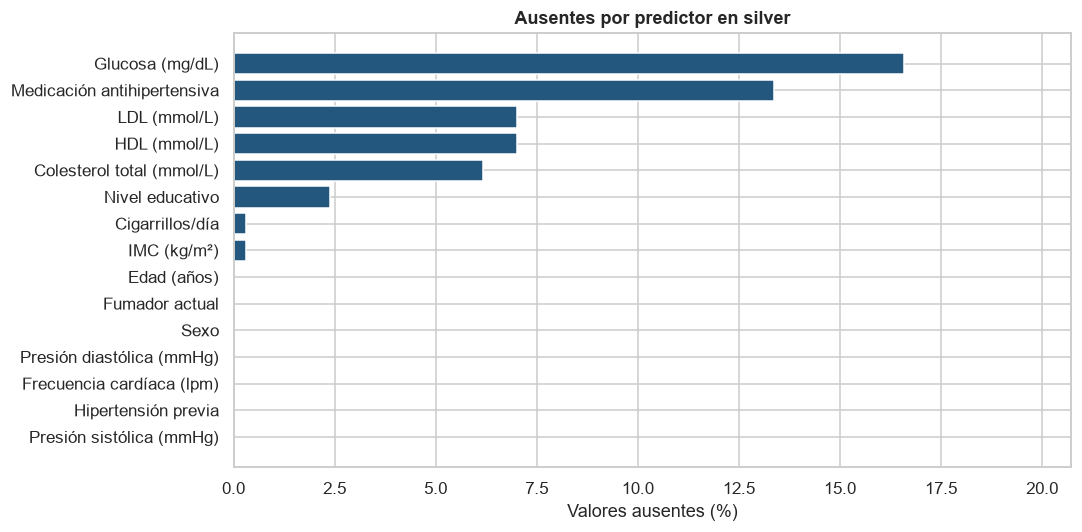

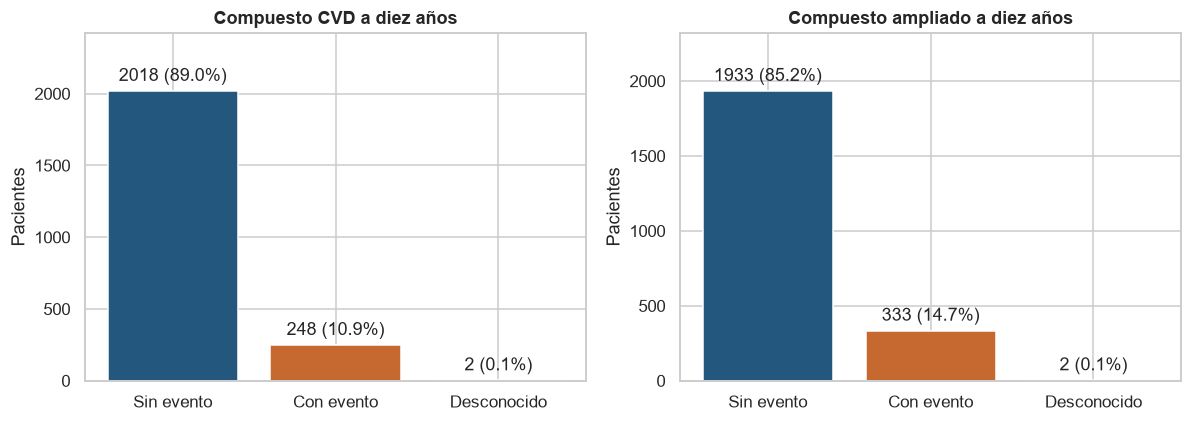

In [12]:
missing_eda = pd.DataFrame({
    'n_missing': eda[eda_features].isna().sum(),
    'pct_missing': eda[eda_features].isna().mean() * 100,
}).sort_values('pct_missing', ascending=False)
summary_eda = eda[CONTINUOUS].describe(percentiles=[.01, .25, .5, .75, .99]).T
missing_eda.to_csv(EDA_DIR / 'missing_predictors.csv', index_label='feature')
summary_eda.to_csv(EDA_DIR / 'continuous_summary.csv', index_label='feature')
display(summary_eda.round(2))
fig, ax = plt.subplots(figsize=(10, 5))
ordered = missing_eda.sort_values('pct_missing')
ax.barh([LABELS[c] for c in ordered.index], ordered.pct_missing, color='#24577D')
ax.set(xlabel='Valores ausentes (%)', title='Ausentes por predictor en silver')
ax.set_xlim(0, max(1, ordered.pct_missing.max() * 1.25))
fig.tight_layout()
eda_show(fig, '01_missing_predictors.png')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
balance_rows = []
for ax, target in zip(axes, eda_targets):
    counts = [int(eda[target].eq(0).sum()), int(eda[target].eq(1).sum()), int(eda[target].isna().sum())]
    bars = ax.bar(['Sin evento', 'Con evento', 'Desconocido'], counts,
                  color=['#24577D', '#C56931', '#9A9A9A'])
    ax.bar_label(bars, labels=[f'{n} ({n/len(eda):.1%})' for n in counts], padding=4)
    ax.set(title=TARGET_LABELS[target] + ' a diez años', ylabel='Pacientes', ylim=(0, max(counts)*1.2))
    balance_rows.append({'target': target, 'negative': counts[0], 'positive': counts[1],
                         'unknown': counts[2], 'positive_rate_known': counts[1] / sum(counts[:2])})
fig.tight_layout()
eda_show(fig, '02_target_balance.png')
pd.DataFrame(balance_rows).to_csv(EDA_DIR / 'target_balance.csv', index=False)

### 7.2 Distribuciones

Valores observados, sin imputar ni recortar extremos.

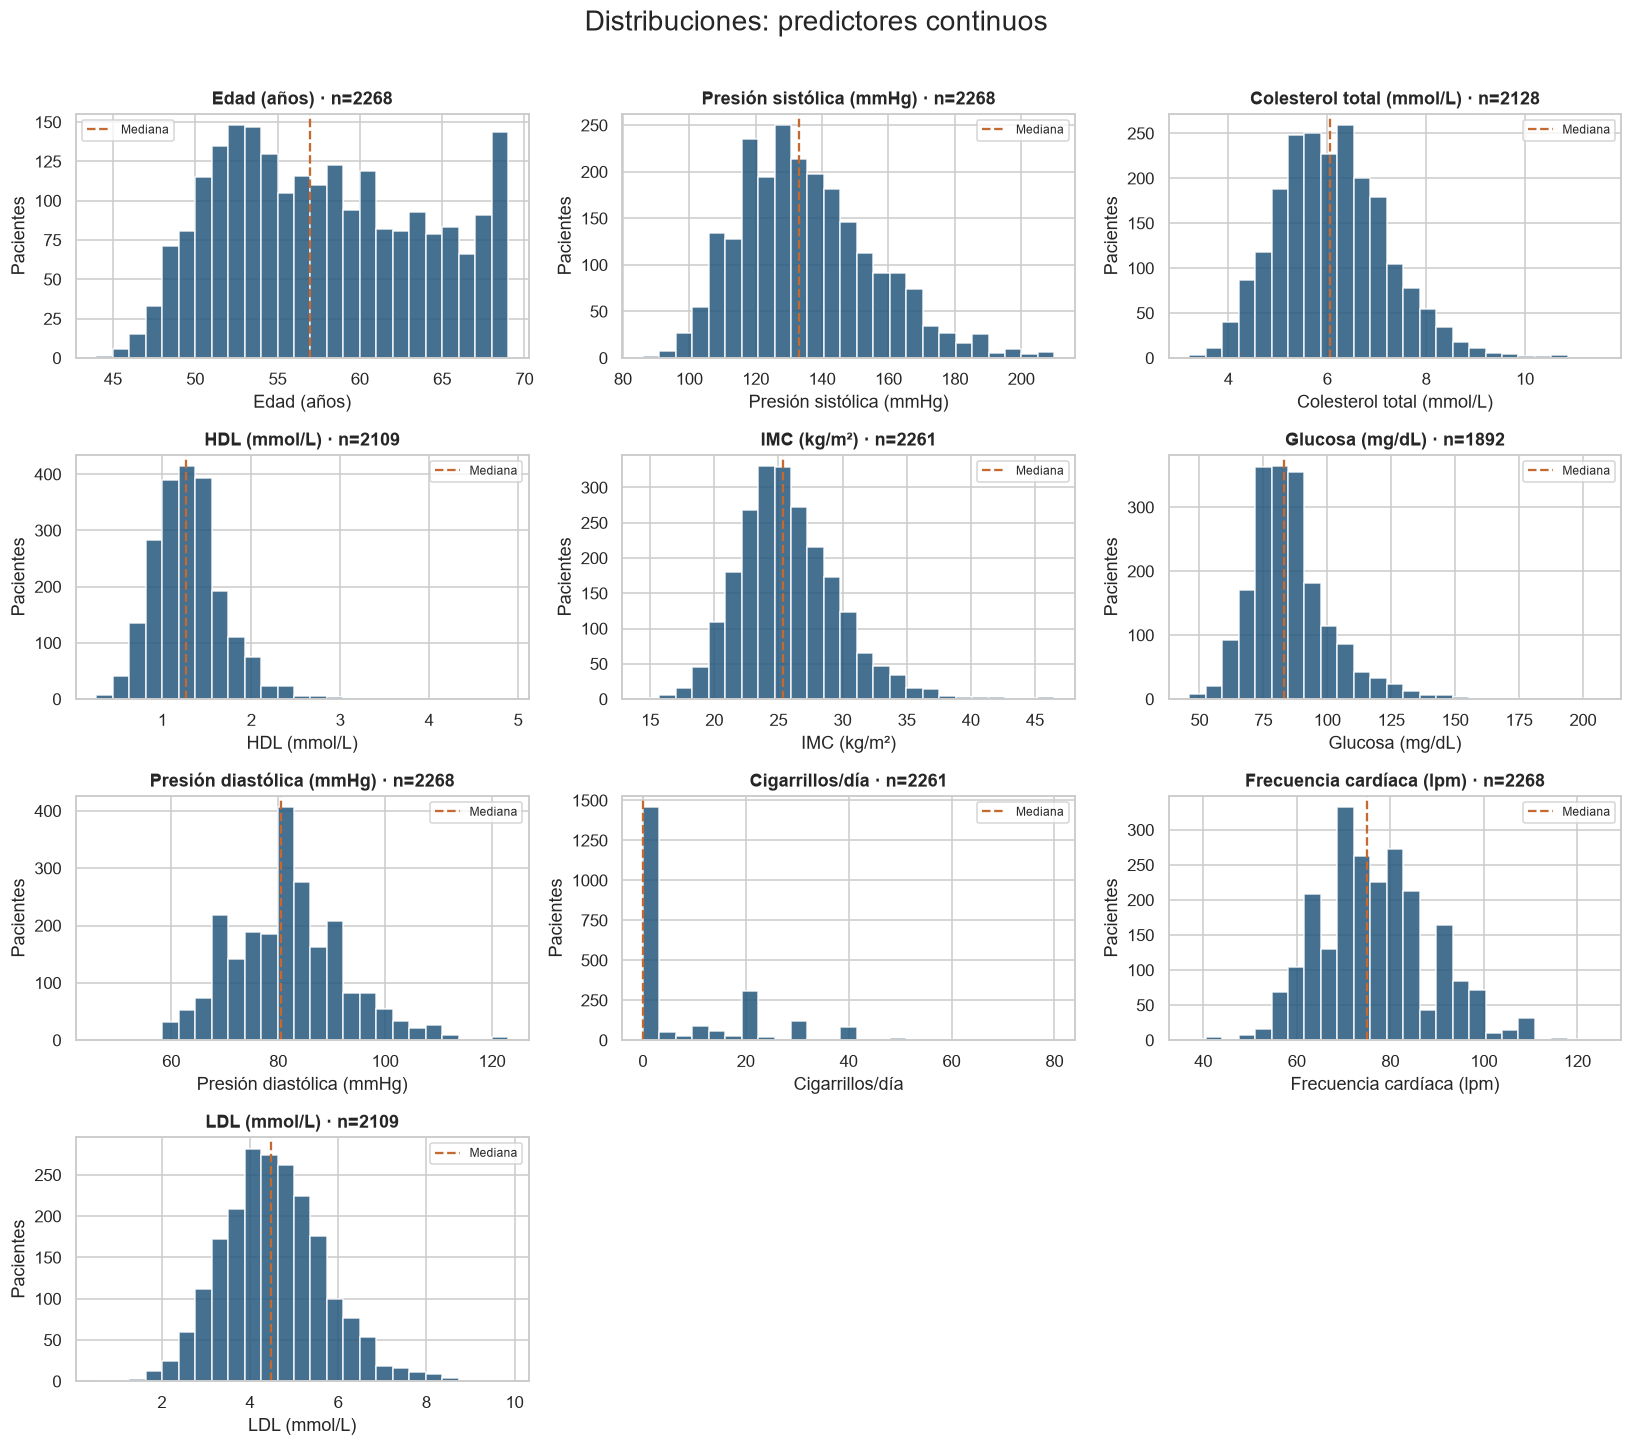

In [13]:
fig, axes = plt.subplots(4, 3, figsize=(15, 13))
for ax, feature in zip(axes.flat, CONTINUOUS):
    values = eda[feature].dropna().astype(float)
    ax.hist(values, bins=25, color='#24577D', alpha=.85, edgecolor='white')
    ax.axvline(values.median(), color='#C56931', linestyle='--', label='Mediana')
    ax.set(title=f'{LABELS[feature]} · n={len(values)}', ylabel='Pacientes', xlabel=LABELS[feature])
    ax.legend(fontsize=8)
for ax in axes.flat[len(CONTINUOUS):]:
    ax.set_visible(False)
fig.suptitle('Distribuciones: predictores continuos', fontsize=18, y=1.01)
fig.tight_layout()
eda_show(fig, '03_predictor_distributions.png')

### 7.3 Correlaciones

Pearson y Spearman con pares disponibles. Se exporta el número de observaciones por par. Solo se usa sexo 0/1 para estas matrices; educación se trata como ordinal. No se incluyen targets ni identificadores.

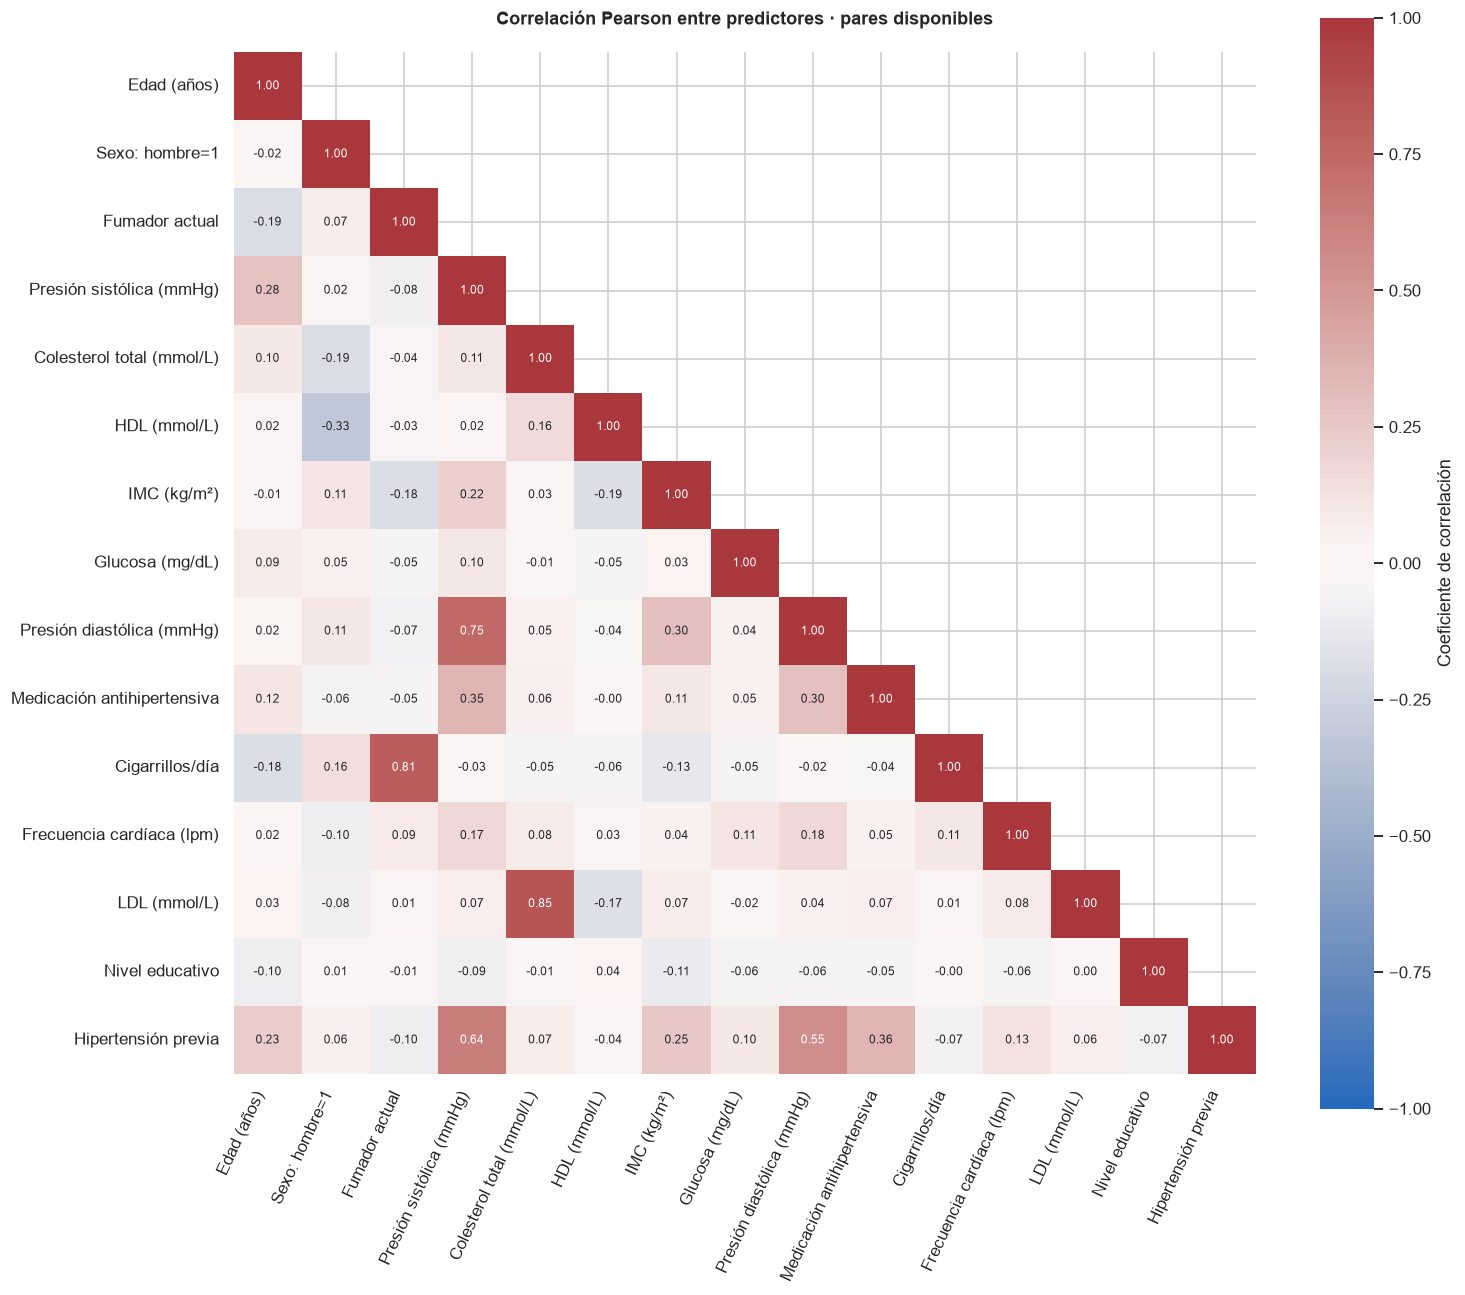

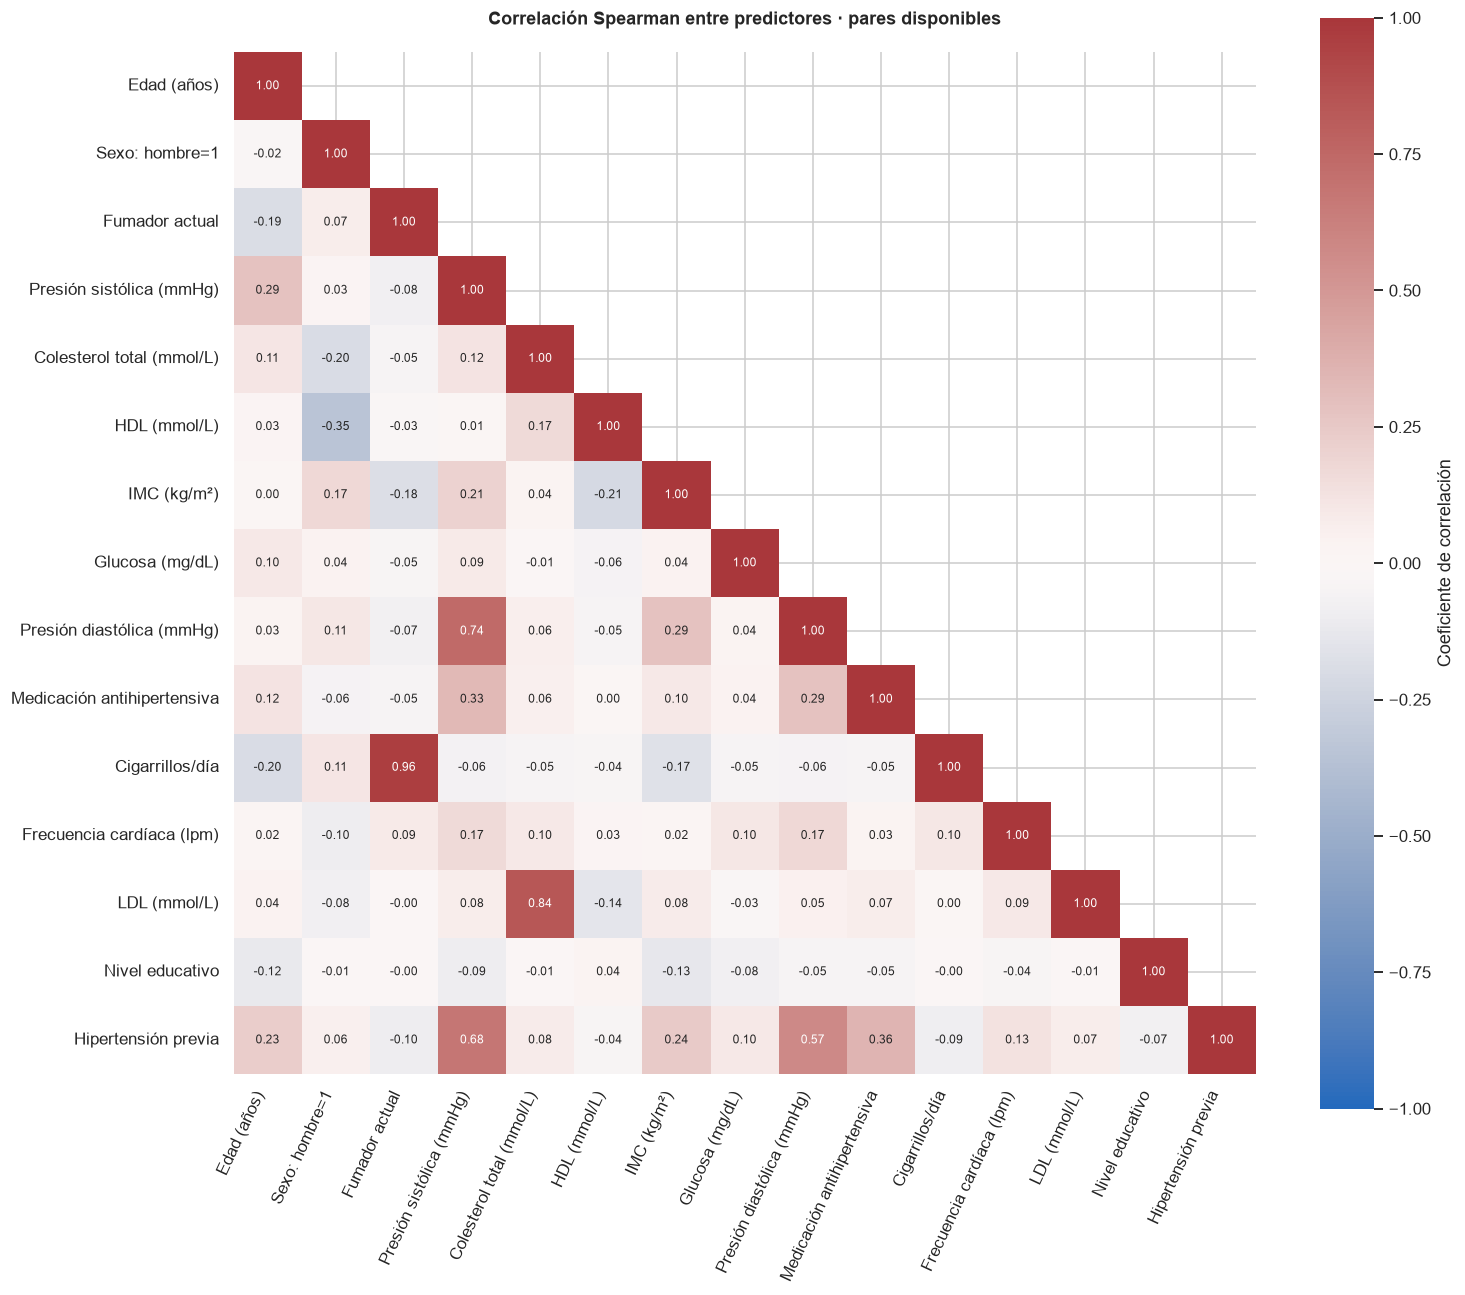

,feature_1,feature_2,pearson,spearman,n_pair,abs_spearman
34,current_smoker,cigarettes_per_day,0.807,0.964,2261,0.964
57,total_cholesterol,ldl_cholesterol,0.851,0.839,2109,0.839
43,systolic_bp,diastolic_bp,0.747,0.739,2268,0.739
49,systolic_bp,previous_hypertension,0.639,0.675,2268,0.675
89,diastolic_bp,previous_hypertension,0.554,0.575,2268,0.575
94,bp_medication,previous_hypertension,0.356,0.356,1965,0.356
17,male_indicator,hdl_cholesterol,-0.326,-0.346,2109,0.346
44,systolic_bp,bp_medication,0.349,0.333,1965,0.333
70,bmi,diastolic_bp,0.303,0.288,2261,0.288
84,diastolic_bp,bp_medication,0.296,0.287,1965,0.287


In [14]:
corr_X = eda[eda_features].copy()
corr_X['sex'] = corr_X['sex'].map({'male': 1.0, 'female': 0.0})
corr_X = corr_X.rename(columns={'sex': 'male_indicator'}).astype(float)
assert len(corr_X.columns) == len(eda_features)
corr_n = corr_X.notna().astype(int).T @ corr_X.notna().astype(int)
corr_n.to_csv(EDA_DIR / 'correlation_pairwise_n.csv')
corr_matrices = {}
for method in ['pearson', 'spearman']:
    corr = corr_X.corr(method=method, min_periods=30)
    corr_matrices[method] = corr
    corr.to_csv(EDA_DIR / f'correlation_{method}.csv')
    plot_corr = corr.rename(index=LABELS, columns=LABELS)
    fig, ax = plt.subplots(figsize=(14, 12))
    sns.heatmap(plot_corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1),
                vmin=-1, vmax=1, center=0, cmap='vlag', annot=True, fmt='.2f',
                annot_kws={'size': 8}, square=True, ax=ax,
                cbar_kws={'label': 'Coeficiente de correlación'})
    ax.set_title(f'Correlación {method.title()} entre predictores · pares disponibles', pad=18)
    ax.tick_params(axis='x', labelrotation=65)
    for label in ax.get_xticklabels(): label.set_horizontalalignment('right')
    fig.tight_layout()
    eda_show(fig, f'04_correlation_{method}.png')

pairs = []
for i, first in enumerate(corr_X.columns):
    for second in corr_X.columns[i+1:]:
        pairs.append({'feature_1': first, 'feature_2': second,
                      'pearson': corr_matrices['pearson'].loc[first, second],
                      'spearman': corr_matrices['spearman'].loc[first, second],
                      'n_pair': int(corr_n.loc[first, second])})
corr_pairs = pd.DataFrame(pairs)
corr_pairs['abs_spearman'] = corr_pairs.spearman.abs()
corr_pairs = corr_pairs.sort_values('abs_spearman', ascending=False)
corr_pairs.to_csv(EDA_DIR / 'correlation_pairs.csv', index=False)
display(corr_pairs.head(12).round(3))

### 7.4 Dotplots por CVD

Un punto por paciente; cajas con mediana y cuartiles. Se excluyen los ausentes de cada variable.

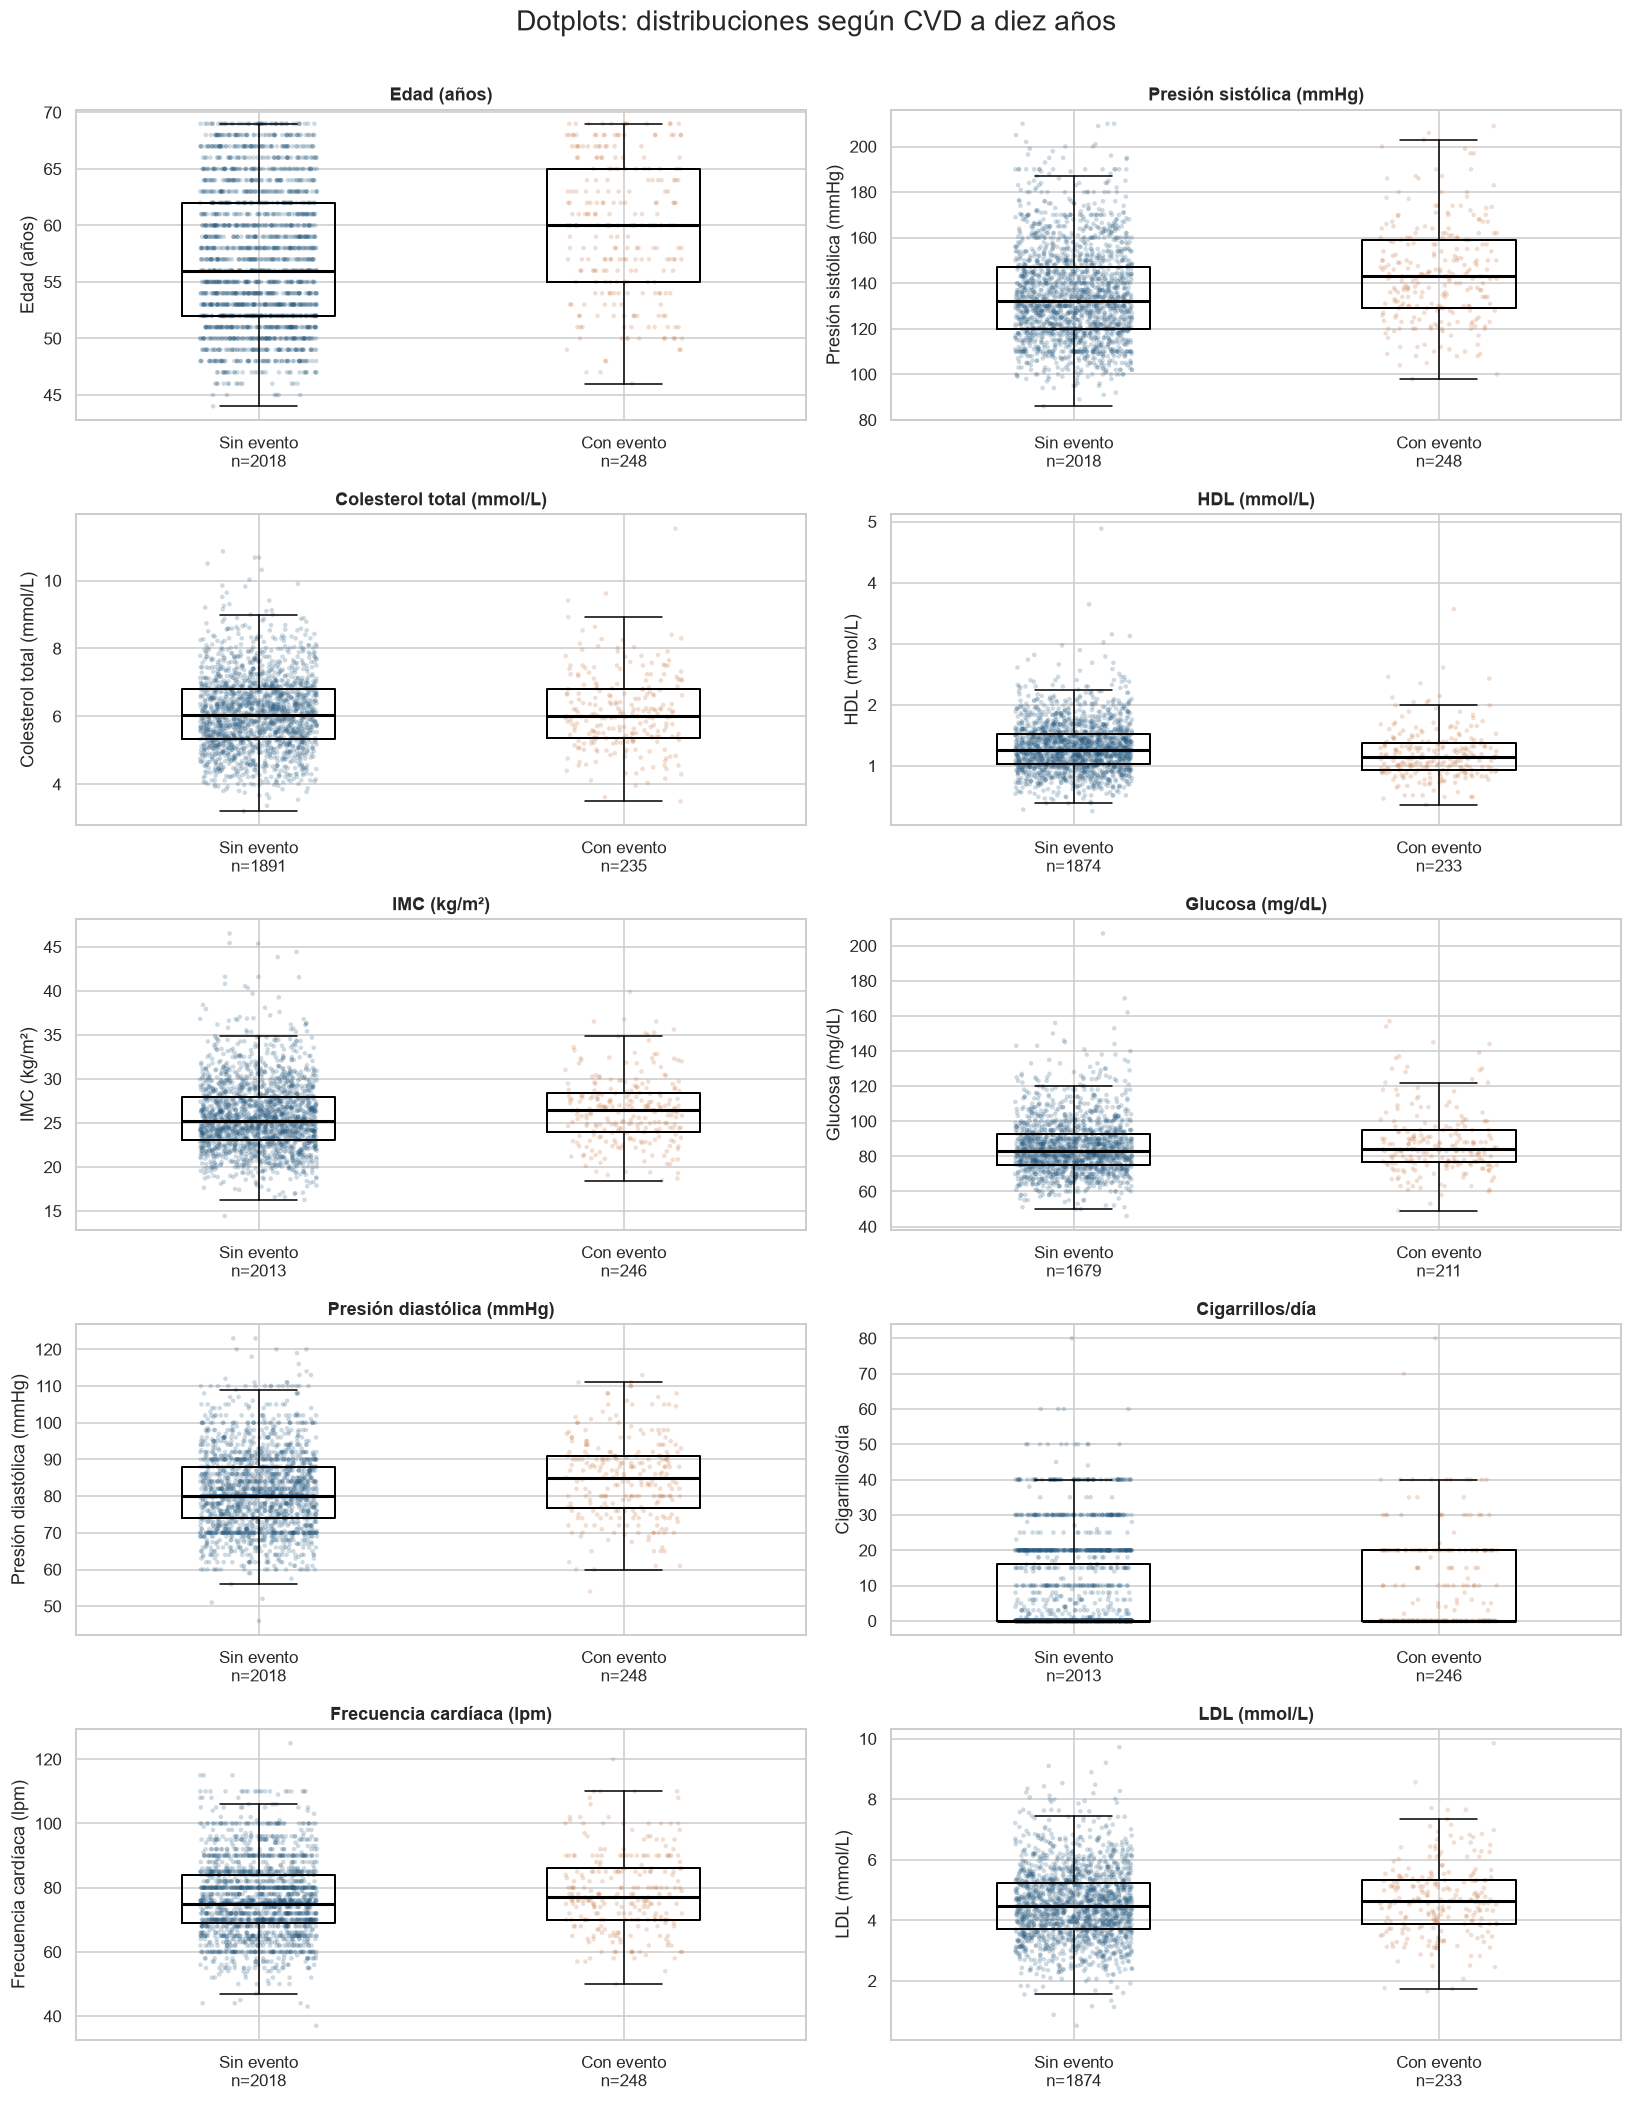

In [15]:
known_cvd = eda.loc[eda.target_cvd_10y.notna()].copy()
rng = np.random.default_rng(42)
fig, axes = plt.subplots(5, 2, figsize=(15, 19))
for ax, feature in zip(axes.flat, CONTINUOUS):
    group_values = []
    tick_labels = []
    for group, color, label in [(0, '#24577D', 'Sin evento'), (1, '#C56931', 'Con evento')]:
        values = known_cvd.loc[known_cvd.target_cvd_10y.eq(group), feature].dropna().astype(float)
        group_values.append(values.to_numpy())
        ax.scatter(group + rng.uniform(-.16, .16, len(values)), values,
                   s=9, alpha=.22, color=color, edgecolors='none', rasterized=True)
        tick_labels.append(f'{label}\nn={len(values)}')
    ax.boxplot(group_values, positions=[0, 1], widths=.42, showfliers=False,
               medianprops={'color': 'black', 'linewidth': 2},
               boxprops={'linewidth': 1.3}, zorder=3)
    ax.set(xticks=[0, 1], xticklabels=tick_labels, ylabel=LABELS[feature],
           title=LABELS[feature], xlim=(-.5, 1.5))
fig.suptitle('Dotplots: distribuciones según CVD a diez años', fontsize=18, y=1.005)
fig.tight_layout()
eda_show(fig, '05_dotplots_by_cvd.png')

### 7.5 Eventos por categoría

Proporciones entre etiquetas conocidas e intervalos de Wilson del 95%, sin ajuste por otras variables.

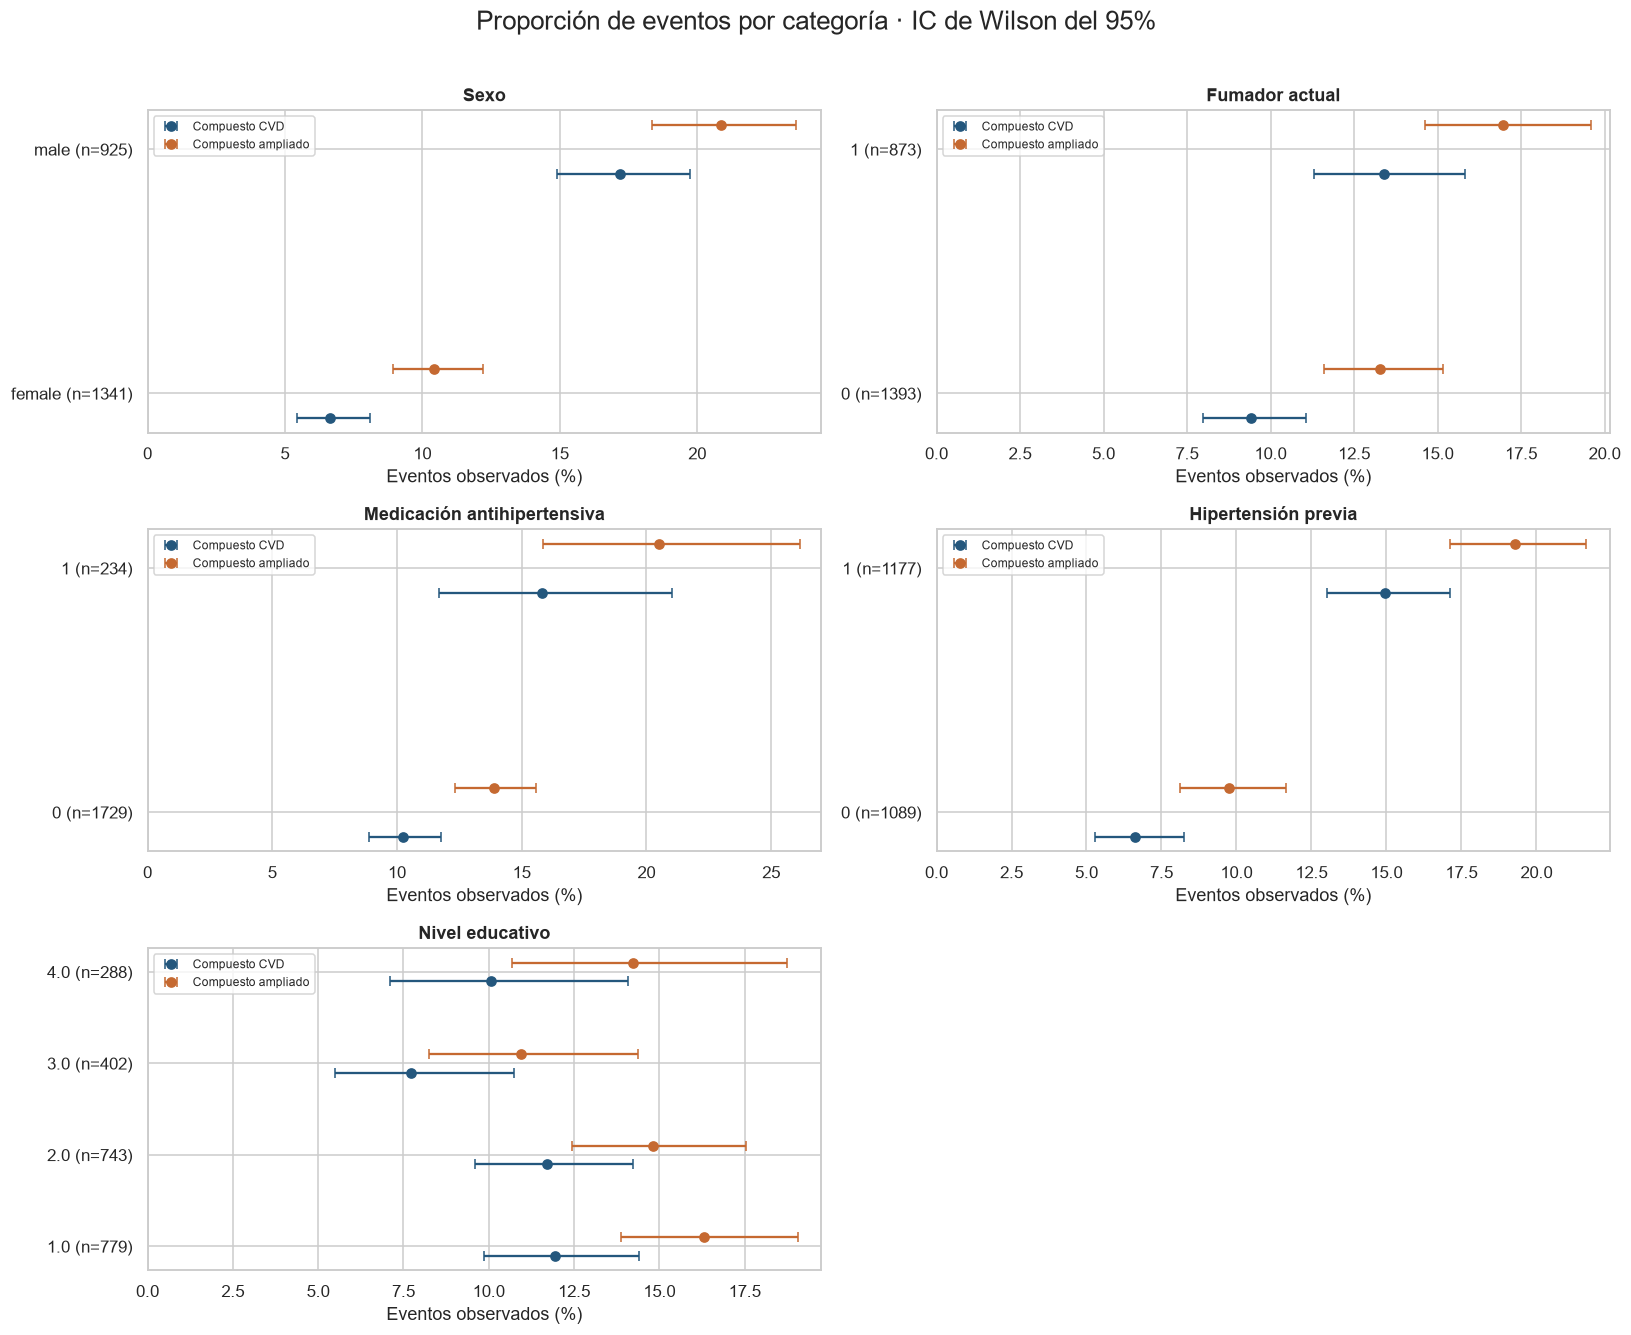

In [16]:
category_rows = []
for feature in CATEGORICAL:
    for target in eda_targets:
        subset = eda.loc[eda[target].notna() & eda[feature].notna(), [feature, target]]
        for category, group in subset.groupby(feature, observed=True):
            n = len(group)
            events = int(group[target].sum())
            p_hat = events / n
            z = 1.959963984540054
            denominator = 1 + z*z/n
            center = (p_hat + z*z/(2*n)) / denominator
            half = z * np.sqrt(p_hat*(1-p_hat)/n + z*z/(4*n*n)) / denominator
            category_rows.append({'feature': feature, 'category': str(category), 'target': target,
                                  'n': n, 'events': events, 'rate': p_hat,
                                  'lower': center-half, 'upper': center+half})
category_rates = pd.DataFrame(category_rows)
category_rates.to_csv(EDA_DIR / 'event_rates_by_category.csv', index=False)
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
for ax, feature in zip(axes.flat, CATEGORICAL):
    feature_rates = category_rates.loc[category_rates.feature.eq(feature)]
    categories = sorted(feature_rates.category.unique())
    for target, color, offset in [('target_cvd_10y', '#24577D', -.1),
                                  ('target_broad_10y', '#C56931', .1)]:
        rows = feature_rates.loc[feature_rates.target.eq(target)].set_index('category').reindex(categories)
        y = np.arange(len(categories)) + offset
        x = rows.rate.to_numpy(dtype=float) * 100
        low = rows.lower.to_numpy(dtype=float) * 100
        high = rows.upper.to_numpy(dtype=float) * 100
        ax.errorbar(x, y, xerr=np.vstack([x-low, high-x]), fmt='o', color=color,
                    capsize=3, label=TARGET_LABELS[target])
    counts = feature_rates.loc[feature_rates.target.eq('target_cvd_10y')].set_index('category')
    labels = [f'{cat} (n={int(counts.loc[cat, "n"])})' for cat in categories]
    ax.set(yticks=np.arange(len(categories)), yticklabels=labels,
           title=LABELS[feature], xlabel='Eventos observados (%)')
    ax.set_xlim(left=0)
    ax.legend(fontsize=8)
for ax in axes.flat[len(CATEGORICAL):]: ax.set_visible(False)
fig.suptitle('Proporción de eventos por categoría · IC de Wilson del 95%', fontsize=17, y=1.01)
fig.tight_layout()
eda_show(fig, '06_event_rate_dotplots.png')

### 7.6 Relaciones entre continuas

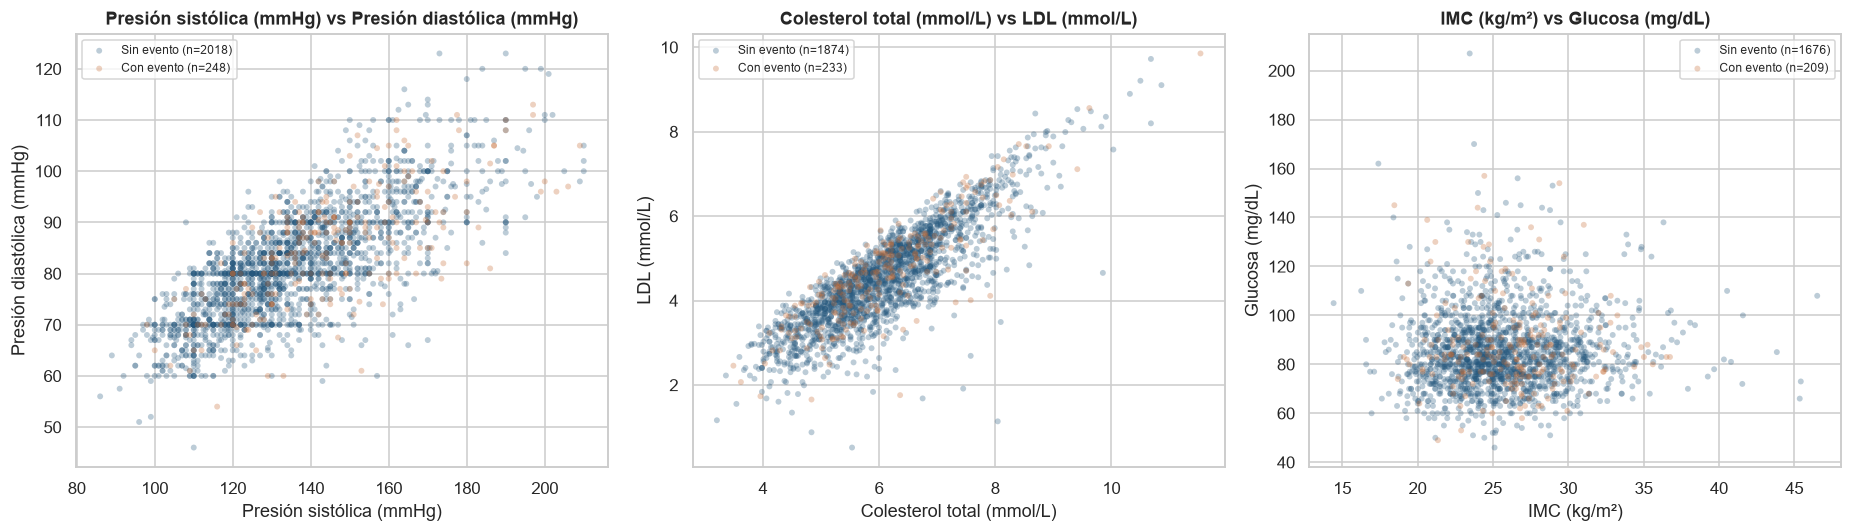

In [17]:
scatter_pairs = [('systolic_bp', 'diastolic_bp'),
                 ('total_cholesterol', 'ldl_cholesterol'), ('bmi', 'glucose')]
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (x_col, y_col) in zip(axes, scatter_pairs):
    for group, color, label in [(0, '#24577D', 'Sin evento'), (1, '#C56931', 'Con evento')]:
        rows = known_cvd.loc[known_cvd.target_cvd_10y.eq(group), [x_col, y_col]].dropna()
        ax.scatter(rows[x_col], rows[y_col], s=15, alpha=.3, color=color,
                   edgecolors='none', label=f'{label} (n={len(rows)})', rasterized=True)
    ax.set(xlabel=LABELS[x_col], ylabel=LABELS[y_col], title=f'{LABELS[x_col]} vs {LABELS[y_col]}')
    ax.legend(fontsize=8)
fig.tight_layout()
eda_show(fig, '07_selected_scatterplots.png')

## 8. Gold: split e imputación

Se usa `target_broad_10y` y se excluyen sus desconocidos. Split estratificado 80/20, semilla 42, con los mismos pacientes en base y plus.

KNN (k=5) imputa continuas usando solo train. Las distancias se calculan tras estandarizar con train y los resultados vuelven a sus unidades clínicas. Base y plus tienen imputadores independientes.

Las categóricas se conservan sin imputar ni codificar. No se eliminan correlacionadas ni se crean características. Antes de entrenar quedan pendientes los nulos categóricos y el sexo en texto.

In [18]:
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer
from sklearn.pipeline import Pipeline

GOLD_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / 'data/silver/manifest.json').exists())
GOLD_DIR = GOLD_ROOT / 'data/gold'
GOLD_TARGET = 'target_broad_10y'
GOLD_SEED = 42
silver_paths = list((GOLD_ROOT / 'data/silver').glob('*'))
silver_hashes_before = {str(p): hashlib.sha256(p.read_bytes()).hexdigest()
                        for p in silver_paths if p.is_file()}
gold_source_manifest = json.loads((GOLD_ROOT / 'data/silver/manifest.json').read_text(encoding='utf-8'))
gold_sources = {
    'score2': pd.read_parquet(GOLD_ROOT / 'data/silver/silver_score2_variables.parquet'),
    'plus': pd.read_parquet(GOLD_ROOT / 'data/silver/silver_plus.parquet'),
}
GOLD_FEATURES = {'score2': gold_source_manifest['base_features'],
                 'plus': gold_source_manifest['plus_features']}
GOLD_CATEGORICAL = ['sex', 'current_smoker', 'bp_medication', 'previous_hypertension', 'education']
GOLD_CONTINUOUS = {name: [c for c in features if c not in GOLD_CATEGORICAL]
                   for name, features in GOLD_FEATURES.items()}
for name, frame in gold_sources.items():
    assert frame.patient_id.is_unique
    assert set(GOLD_FEATURES[name]).isdisjoint(['patient_id', 'target_cvd_10y', GOLD_TARGET])
pd.testing.assert_frame_equal(gold_sources['score2'],
                             gold_sources['plus'][gold_sources['score2'].columns])

### 8.1 Split

Primero se excluyen etiquetas desconocidas y se separan pacientes. El target alternativo no se exporta a gold.

In [19]:
gold_population = gold_sources['plus'].set_index('patient_id')
known_target = gold_population[GOLD_TARGET].notna()
eligible_ids = gold_population.index[known_target]
excluded_ids = gold_population.index[~known_target]
y_known = gold_population.loc[eligible_ids, GOLD_TARGET].astype('int64')
train_ids, test_ids = train_test_split(
    eligible_ids.to_numpy(), test_size=0.20, random_state=GOLD_SEED, stratify=y_known.to_numpy()
)
assert set(train_ids).isdisjoint(test_ids)
assert set(train_ids) | set(test_ids) == set(eligible_ids)
assert set(excluded_ids).isdisjoint(set(train_ids) | set(test_ids))
split_rows = []
for split_name, ids in [('train', train_ids), ('test', test_ids)]:
    y_split = gold_population.loc[ids, GOLD_TARGET].astype('int64')
    split_rows.append({'split': split_name, 'patients': len(ids),
                       'negatives': int(y_split.eq(0).sum()), 'positives': int(y_split.eq(1).sum()),
                       'positive_rate': float(y_split.mean())})
split_summary = pd.DataFrame(split_rows)
assert split_summary.positives.sum() == int(y_known.sum())
assert abs(split_summary.iloc[0].positive_rate - split_summary.iloc[1].positive_rate) < 0.01
print(f'Excluidos por target desconocido: {len(excluded_ids)}')
display(split_summary)

Excluidos por target desconocido: 2


,split,patients,negatives,positives,positive_rate
0,train,1812,1546,266,0.146799
1,test,454,387,67,0.147577


### 8.2 KNN

Test busca vecinos solo en train. Los valores ya observados no cambian. Para futura validación cruzada, el preprocesamiento debe reajustarse dentro de cada fold.

In [20]:
def transform_gold_continuous(frame, artifact):
    columns = artifact['continuous_columns']
    original = frame[columns].astype(float)
    scaled_imputed = artifact['distance_pipeline'].transform(original)
    restored = artifact['distance_pipeline'].named_steps['scale'].inverse_transform(scaled_imputed)
    imputed = pd.DataFrame(restored, index=frame.index, columns=columns)
    result = frame.copy()
    for column in columns:
        # Solo rellenar huecos: no alterar observaciones por redondeos al invertir el escalado.
        result[column] = original[column].where(original[column].notna(), imputed[column])
    return result

gold_frames = {}
gold_preprocessors = {}
imputation_rows = []
for name, source in gold_sources.items():
    features = GOLD_FEATURES[name]
    continuous = GOLD_CONTINUOUS[name]
    categorical = [c for c in features if c in GOLD_CATEGORICAL]
    indexed = source.set_index('patient_id')
    X_train = indexed.loc[train_ids, features].copy()
    X_test = indexed.loc[test_ids, features].copy()
    assert not X_train[continuous].isna().all().any(), 'Una continua no tiene datos en train.'
    pipeline = Pipeline([
        ('scale', StandardScaler()),
        ('knn', KNNImputer(n_neighbors=5, weights='uniform', metric='nan_euclidean')),
    ])
    pipeline.fit(X_train[continuous].astype(float))
    artifact = {'distance_pipeline': pipeline, 'continuous_columns': continuous,
                'feature_columns': features, 'categorical_columns_pending': categorical,
                'output_units': 'inverse_transform scale to silver clinical units'}
    gold_preprocessors[name] = artifact
    for split_name, X in [('train', X_train), ('test', X_test)]:
        prepared = transform_gold_continuous(X, artifact)
        assert not prepared[continuous].isna().any().any()
        assert np.isfinite(prepared[continuous].to_numpy(dtype=float)).all()
        pd.testing.assert_frame_equal(prepared[categorical], X[categorical])
        for column in continuous:
            observed = X[column].notna()
            np.testing.assert_array_equal(prepared.loc[observed, column].to_numpy(),
                                          X.loc[observed, column].to_numpy())
        for column in continuous:
            imputation_rows.append({'dataset': name, 'split': split_name, 'feature': column,
                                    'missing_before': int(X[column].isna().sum()),
                                    'missing_after': int(prepared[column].isna().sum())})
        prepared[GOLD_TARGET] = indexed.loc[X.index, GOLD_TARGET].astype('int64')
        gold_frames[(name, split_name)] = prepared.reset_index()
        assert list(prepared.columns) == [*features, GOLD_TARGET]
        assert prepared[GOLD_TARGET].isin([0, 1]).all()
imputation_summary = pd.DataFrame(imputation_rows)
display(imputation_summary.loc[imputation_summary.missing_before.gt(0)])

,dataset,split,feature,missing_before,missing_after
2,score2,train,total_cholesterol,111,0
3,score2,train,hdl_cholesterol,126,0
6,score2,test,total_cholesterol,29,0
7,score2,test,hdl_cholesterol,33,0
10,plus,train,total_cholesterol,111,0
11,plus,train,hdl_cholesterol,126,0
12,plus,train,bmi,4,0
13,plus,train,glucose,305,0
15,plus,train,cigarettes_per_day,6,0
17,plus,train,ldl_cholesterol,126,0


### 8.3 Categóricas

Sexo, tabaquismo, medicación e hipertensión previa son binarias. Educación es ordinal (1–4). Se muestran categorías y nulos sin transformarlas.

In [21]:
categorical_rows = []
for split_name in ['train', 'test']:
    frame = gold_frames[('plus', split_name)]
    for column in GOLD_CATEGORICAL:
        categorical_rows.append({
            'feature': column, 'split': split_name,
            'kind': 'ordinal' if column == 'education' else 'binary',
            'categories': ', '.join(map(str, sorted(frame[column].dropna().unique()))),
            'missing': int(frame[column].isna().sum()),
            'missing_pct': float(frame[column].isna().mean() * 100),
        })
categorical_inventory = pd.DataFrame(categorical_rows)
display(categorical_inventory)

,feature,split,kind,categories,missing,missing_pct
0,sex,train,binary,"female, male",0,0.000000
1,current_smoker,train,binary,"0, 1",0,0.000000
2,bp_medication,train,binary,"0, 1",242,13.355408
3,previous_hypertension,train,binary,"0, 1",0,0.000000
4,education,train,ordinal,"1.0, 2.0, 3.0, 4.0",39,2.152318
5,sex,test,binary,"female, male",0,0.000000
6,current_smoker,test,binary,"0, 1",0,0.000000
7,bp_medication,test,binary,"0, 1",61,13.436123
8,previous_hypertension,test,binary,"0, 1",0,0.000000
9,education,test,ordinal,"1.0, 2.0, 3.0, 4.0",15,3.303965


### 8.4 Guardar gold

Cuatro tablas (base/plus × train/test) y dos imputadores. `patient_id` permite identificar pacientes, pero no entra como predictor. Seleccionar X con `GOLD_FEATURES`.

In [22]:
GOLD_DIR.mkdir(parents=True, exist_ok=True)
(GOLD_DIR / 'preprocessing').mkdir(exist_ok=True)
for (name, split_name), frame in gold_frames.items():
    path = GOLD_DIR / f'gold_{name}_{split_name}.parquet'
    frame.to_parquet(path, index=False)
    pd.testing.assert_frame_equal(frame, pd.read_parquet(path))
for split_name in ['train', 'test']:
    base = gold_frames[('score2', split_name)]
    plus = gold_frames[('plus', split_name)]
    pd.testing.assert_frame_equal(base[['patient_id', GOLD_TARGET]], plus[['patient_id', GOLD_TARGET]])
for name, artifact in gold_preprocessors.items():
    artifact_path = GOLD_DIR / 'preprocessing' / f'knn_{name}.joblib'
    joblib.dump(artifact, artifact_path)
    restored_artifact = joblib.load(artifact_path)
    input_test = gold_sources[name].set_index('patient_id').loc[test_ids, GOLD_FEATURES[name]]
    pd.testing.assert_frame_equal(transform_gold_continuous(input_test, artifact),
                                  transform_gold_continuous(input_test, restored_artifact))
assert silver_hashes_before == {str(p): hashlib.sha256(p.read_bytes()).hexdigest()
                                 for p in silver_paths if p.is_file()}
print('Gold parcial guardado. Continuas imputadas; categoricas pendientes. Silver intacto.')

Gold parcial guardado. Continuas imputadas; categoricas pendientes. Silver intacto.
